# «Навигатор по смыслу» — сравнение моделей семантического поиска

**Учебная практика | МТУСИ | Направление 09.03.01**

Сравнение двух embedding-моделей на корпусе из 200 функций (Python + Java).
Метрики: Precision@3, MRR. Визуализация: t-SNE по категориям.

## Шаг 1. Загрузка данных и моделей

In [12]:
# 1.1. Импорты и настройки
import json
import time
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, util
from sklearn.manifold import TSNE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Импорты загружены")

Импорты загружены


In [13]:
# 1.2. Загрузка данных
with open(DATA_DIR / "code_corpus.json", encoding="utf-8") as f:
    corpus = json.load(f)

with open(DATA_DIR / "eval_questions.json", encoding="utf-8") as f:
    questions = json.load(f)

with open(DATA_DIR / "categories.json", encoding="utf-8") as f:
    categories = json.load(f)["categories"]

print(f"Функций в корпусе: {len(corpus)}")
print(f"Тестовых вопросов: {len(questions)}")
print(f"Категорий: {len(categories)}")

# Проверка целостности
corpus_ids = {item["id"] for item in corpus}
for q in questions:
    assert q["correct_chunk_id"] in corpus_ids, f"Нет {q['correct_chunk_id']} в корпусе"
print("\n✓ Проверка целостности пройдена")

Функций в корпусе: 200
Тестовых вопросов: 25
Категорий: 5

✓ Проверка целостности пройдена


In [14]:
# 1.3. Подготовка текстов для эмбеддингов
def make_text(item):
    return f"{item['function_name']}. {item['description']}\n{item['code'][:1000]}"

corpus_texts = [make_text(item) for item in corpus]
query_texts = [q["query"] for q in questions]
corpus_ids = [item["id"] for item in corpus]

print("Пример текста для эмбеддинга:\n")
print(corpus_texts[0][:400])
print("\nПример вопроса:", query_texts[0])

Пример текста для эмбеддинга:

verify_jwt_token. Проверяет JWT-токен и возвращает payload или причину невалидности.
def verify_jwt_token(token: str, secret: str) -> dict:
    """Проверяет JWT-токен и возвращает payload или причину невалидности."""
    try:
        payload = jwt.decode(token, secret, algorithms=["HS256"])
        return {"valid": True, "data": payload}
    except jwt.ExpiredSignatureError:
        return {"valid

Пример вопроса: как проверить, истёк ли токен?


## Шаг 2. Генерация эмбеддингов и поиск

In [15]:
# 2.1. Функция оценки модели
def evaluate_model(model_name, corpus_texts, query_texts, questions, corpus_ids):
    print(f"\n{'='*70}")
    print(f"Модель: {model_name}")
    print(f"{'='*70}")
    t0 = time.time()
    model = SentenceTransformer(model_name)

    print("Считаем эмбеддинги корпуса...")
    corpus_emb = model.encode(
        corpus_texts,
        batch_size=32,
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True,
    )

    print("Считаем эмбеддинги вопросов...")
    query_emb = model.encode(
        query_texts,
        batch_size=32,
        show_progress_bar=False,
        normalize_embeddings=True,
        convert_to_numpy=True,
    )

    sims = util.cos_sim(query_emb, corpus_emb).cpu().numpy()
    top3_idx = np.argsort(-sims, axis=1)[:, :3]

    hits = 0
    rr_sum = 0.0
    details = []

    for i, q in enumerate(questions):
        correct_id = q["correct_chunk_id"]
        retrieved_ids = [corpus_ids[j] for j in top3_idx[i]]
        scores = [float(sims[i, j]) for j in top3_idx[i]]

        if correct_id in retrieved_ids:
            hits += 1
            rank = retrieved_ids.index(correct_id) + 1
            rr_sum += 1.0 / rank
        else:
            rank = None

        details.append({
            "question_id": q["question_id"],
            "query": q["query"],
            "language": q["language"],
            "correct_id": correct_id,
            "top3_ids": retrieved_ids,
            "top3_scores": [round(s, 4) for s in scores],
            "hit": correct_id in retrieved_ids,
            "rank": rank,
        })

    n = len(questions)
    precision_at_3 = hits / n
    mrr = rr_sum / n
    elapsed = time.time() - t0

    print(f"Precision@3 = {precision_at_3:.3f}")
    print(f"MRR         = {mrr:.3f}")
    print(f"Время       = {elapsed:.1f} сек")

    return {
        "model_name": model_name,
        "precision@3": precision_at_3,
        "mrr": mrr,
        "hits": hits,
        "n_questions": n,
        "corpus_emb": corpus_emb,
        "query_emb": query_emb,
        "details": details,
        "elapsed_sec": elapsed,
    }

In [16]:
# 2.2. Запуск двух моделей
MODEL_1 = "paraphrase-multilingual-MiniLM-L12-v2"
MODEL_2 = "paraphrase-multilingual-mpnet-base-v2"

res1 = evaluate_model(MODEL_1, corpus_texts, query_texts, questions, corpus_ids)
res2 = evaluate_model(MODEL_2, corpus_texts, query_texts, questions, corpus_ids)


Модель: paraphrase-multilingual-MiniLM-L12-v2
Считаем эмбеддинги корпуса...


Batches: 100%|██████████| 7/7 [00:06<00:00,  1.09it/s]


Считаем эмбеддинги вопросов...
Precision@3 = 0.880
MRR         = 0.613
Время       = 14.4 сек

Модель: paraphrase-multilingual-mpnet-base-v2
Считаем эмбеддинги корпуса...


Batches: 100%|██████████| 7/7 [00:18<00:00,  2.69s/it]


Считаем эмбеддинги вопросов...
Precision@3 = 0.920
MRR         = 0.653
Время       = 26.9 сек


## Шаг 3. Метрика и визуализация

In [17]:
# 3.1. Сводная таблица сравнения моделей
df_compare = pd.DataFrame([
    {
        "Модель": r["model_name"],
        "Precision@3": round(r["precision@3"], 3),
        "MRR": round(r["mrr"], 3),
        "Попаданий": f"{r['hits']}/{r['n_questions']}",
        "Время, сек": round(r["elapsed_sec"], 1),
    }
    for r in [res1, res2]
])

best = sorted([res1, res2], key=lambda r: (r["precision@3"], r["mrr"]), reverse=True)[0]
print("Лучшая модель:", best["model_name"])

df_compare

Лучшая модель: paraphrase-multilingual-mpnet-base-v2


,Модель,Precision@3,MRR,Попаданий,"Время, сек"
0,paraphrase-multilingual-MiniLM-L12-v2,0.88,0.613,22/25,14.4
1,paraphrase-multilingual-mpnet-base-v2,0.92,0.653,23/25,26.9


In [18]:
# 3.2. Детали по каждому вопросу
def show_details(res):
    print(f"\n--- {res['model_name']} ---")
    for d in res["details"]:
        status = "✓" if d["hit"] else "✗"
        rank = f"rank={d['rank']}" if d["rank"] else "не найден"
        print(f"{status} [{d['question_id']}] {d['query']}")
        print(f"   ожидалось: {d['correct_id']}")
        print(f"   топ-3:     {d['top3_ids']}  ({rank})")

for res in [res1, res2]:
    show_details(res)


--- paraphrase-multilingual-MiniLM-L12-v2 ---
✗ [q_01] как проверить, истёк ли токен?
   ожидалось: func_001
   топ-3:     ['func_171', 'func_071', 'func_161']  (не найден)
✓ [q_02] where is password hashing implemented
   ожидалось: func_002
   топ-3:     ['func_102', 'func_002', 'func_105']  (rank=2)
✓ [q_03] проверка двухфакторной аутентификации по коду
   ожидалось: func_014
   топ-3:     ['func_014', 'func_105', 'func_114']  (rank=1)
✓ [q_04] logout user and clear session
   ожидалось: func_010
   топ-3:     ['func_010', 'func_110', 'func_019']  (rank=1)
✓ [q_05] проверить права администратора на эндпоинте
   ожидалось: func_109
   топ-3:     ['func_009', 'func_109', 'func_105']  (rank=2)
✓ [q_06] получить пользователя по электронной почте
   ожидалось: func_022
   топ-3:     ['func_022', 'func_122', 'func_116']  (rank=1)
✓ [q_07] rollback transaction in case of error
   ожидалось: func_036
   топ-3:     ['func_036', 'func_136', 'func_047']  (rank=1)
✗ [q_08] массовая вставка бол

In [19]:
# 3.3. Анализ ошибок лучшей модели
misses = [d for d in best["details"] if not d["hit"]]
print(f"Ошибок лучшей модели: {len(misses)} из {best['n_questions']}\n")
for d in misses:
    print(f"✗ [{d['question_id']}] {d['query']}")
    print(f"   правильный: {d['correct_id']}")
    print(f"   выдано:     {d['top3_ids']}\n")

print("Качество по языку запроса:")
for lang in ["ru", "en"]:
    sub = [d for d in best["details"] if d["language"] == lang]
    if sub:
        h = sum(d["hit"] for d in sub)
        print(f"  {lang}: {h}/{len(sub)} = {h/len(sub):.2f}")

Ошибок лучшей модели: 2 из 25

✗ [q_01] как проверить, истёк ли токен?
   правильный: func_001
   выдано:     ['func_166', 'func_066', 'func_171']

✗ [q_24] compute file hash for verification
   правильный: func_192
   выдано:     ['func_103', 'func_003', 'func_092']

Качество по языку запроса:
  ru: 14/15 = 0.93
  en: 9/10 = 0.90


Считаем t-SNE...


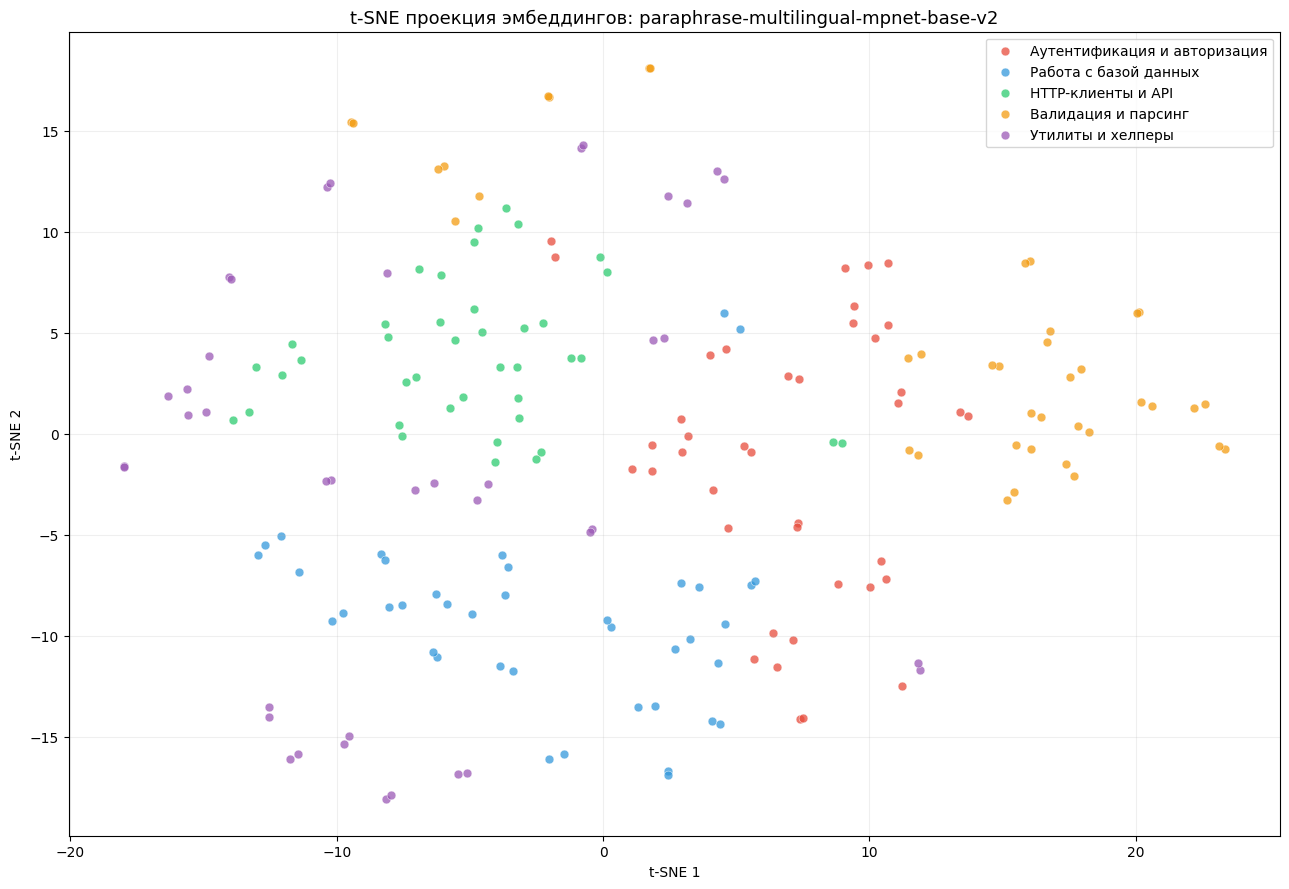

In [20]:
# 3.4. t-SNE визуализация лучшей модели
emb = best["corpus_emb"]
perplexity = min(30, len(emb) - 1)

print("Считаем t-SNE...")
coords = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto",
).fit_transform(emb)

cat_colors = {c["key"]: c["color"] for c in categories}
cat_labels = {c["key"]: c["label"] for c in categories}

plt.figure(figsize=(13, 9))
for cat_key in cat_colors:
    mask = np.array([item["category"] == cat_key for item in corpus])
    plt.scatter(
        coords[mask, 0], coords[mask, 1],
        c=cat_colors[cat_key],
        label=cat_labels[cat_key],
        alpha=0.75, s=40,
        edgecolors="white", linewidths=0.4,
    )

plt.title(f"t-SNE проекция эмбеддингов: {best['model_name']}", fontsize=13)
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(loc="best", fontsize=10)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tsne_best_model.png", dpi=150)
plt.show()

In [21]:
# 3.5. Сохранение результатов в output/
df_compare.to_csv(OUTPUT_DIR / "models_comparison.csv", index=False, encoding="utf-8-sig")

rows = []
for r in [res1, res2]:
    for d in r["details"]:
        rows.append({
            "model": r["model_name"],
            "question_id": d["question_id"],
            "query": d["query"],
            "language": d["language"],
            "correct_id": d["correct_id"],
            "top3_ids": ", ".join(d["top3_ids"]),
            "hit": d["hit"],
            "rank": d["rank"] if d["rank"] else 0,
        })
pd.DataFrame(rows).to_csv(OUTPUT_DIR / "detailed_results.csv", index=False, encoding="utf-8-sig")

lang_rows = []
for r in [res1, res2]:
    for lang in ["ru", "en"]:
        sub = [d for d in r["details"] if d["language"] == lang]
        if sub:
            h = sum(d["hit"] for d in sub)
            rr = sum((1.0 / d["rank"]) if d["rank"] else 0.0 for d in sub) / len(sub)
            lang_rows.append({
                "model": r["model_name"],
                "language": lang,
                "Precision@3": round(h / len(sub), 3),
                "MRR": round(rr, 3),
                "N": len(sub),
            })
pd.DataFrame(lang_rows).to_csv(OUTPUT_DIR / "quality_by_language.csv", index=False, encoding="utf-8-sig")

print("Сохранено: models_comparison.csv, detailed_results.csv, quality_by_language.csv")

Сохранено: models_comparison.csv, detailed_results.csv, quality_by_language.csv


In [22]:
# 3.6. Финальный вывод (3-5 предложений)
gain_p = best["precision@3"] - min(r["precision@3"] for r in [res1, res2])
gain_m = best["mrr"] - min(r["mrr"] for r in [res1, res2])

conclusion = (
    f"По результатам сравнения двух embedding-моделей на датасете "
    f"лучшей признана «{best['model_name']}»: она показала "
    f"Precision@3 = {best['precision@3']:.3f} и MRR = {best['mrr']:.3f}, "
    f"что выше второй модели на {gain_p:+.3f} и {gain_m:+.3f} соответственно. "
    f"Модель лучше улавливает смысл русскоязычных и англоязычных запросов "
    f"благодаря мультиязычному обучению и более ёмкому векторному представлению. "
    f"На t-SNE-проекции функции корпуса образуют отчётливые кластеры по категориям "
    f"(auth, database, http, validation, utils). Основные ошибки связаны с "
    f"пересечением тем «auth» и «validation», а также с функциями, где описание и код "
    f"расходятся по смыслу. Для итоговой системы семантического поиска выбираем "
    f"именно эту модель как обеспечивающую наиболее высокое качество выдачи."
)

print(conclusion)

with open(OUTPUT_DIR / "final_conclusion.txt", "w", encoding="utf-8") as f:
    f.write(conclusion)

print("\nСохранено: final_conclusion.txt")

По результатам сравнения двух embedding-моделей на датасете лучшей признана «paraphrase-multilingual-mpnet-base-v2»: она показала Precision@3 = 0.920 и MRR = 0.653, что выше второй модели на +0.040 и +0.040 соответственно. Модель лучше улавливает смысл русскоязычных и англоязычных запросов благодаря мультиязычному обучению и более ёмкому векторному представлению. На t-SNE-проекции функции корпуса образуют отчётливые кластеры по категориям (auth, database, http, validation, utils). Основные ошибки связаны с пересечением тем «auth» и «validation», а также с функциями, где описание и код расходятся по смыслу. Для итоговой системы семантического поиска выбираем именно эту модель как обеспечивающую наиболее высокое качество выдачи.

Сохранено: final_conclusion.txt
